# Start Here: Quantum Computing Explained Simply

> **Who is this for:** complete beginners. You have heard "quantum computing", "quantum AI" or "quantum machine learning" and want to understand what they mean, without any physics background. If you can add, multiply and run a Python cell, you can follow this notebook.
>
> **What you will learn:**
> - what an ordinary computer does with **bits**, and what is different about **qubits**
> - three everyday pictures (a **spinning coin**, **ripples on water**, a **maze where wrong paths cancel**) and exactly where each picture stops being true
> - the tiny bit of maths you need, taught from zero with numbers you can check by hand: **complex numbers** (just enough), **vectors** as arrows or lists, **matrices** as "machines that transform vectors", and **probabilities as squared lengths**
> - a **qubit** as a list of 2 numbers, a **gate** as a 2x2 matrix, and **measurement** as random sampling (a coin and a qubit, simulated side by side)
> - why the list **doubles** with every qubit you add (2, 4, 8, ... $2^n$)
> - **entanglement** in plain words, with a simulated **Bell pair**
> - **interference**: why H followed by H brings a qubit back to 0
> - common **myths vs facts**, and a map of **Quantum Computing vs Quantum AI vs Quantum ML**
> - a **glossary** of 20 terms and a **self-check quiz** with answers
>
> **Prerequisites:** none beyond basic Python. If Python is new, see [Python basics](../01_Python/01_basic.ipynb). Helpful but optional: [maths notation bridge](../14_Mathematics/00_start_here_math_notation_bridge.ipynb).
>
> **Time needed:** about 1-1.5 hours to read and play. The notebook runs in a few seconds.
>
> **Runs on:** CPU, no API key, no internet. Only numpy and matplotlib.

**Where this fits.** This is the start point of the `25_Quantum_AI` track. The track has two parts:

| Part | Notebooks | Question it answers |
|---|---|---|
| **Part 1: Quantum Computing** | **00 (this one)**, [01 basics](01_quantum_computing_basics.ipynb), [02 algorithms](02_quantum_algorithms.ipynb) | What is a quantum computer and what is it good for? |
| **Part 2: Quantum AI and Quantum ML** | [03 quantum ML](03_quantum_machine_learning.ipynb), [04 tools, hardware and industry](04_quantum_ai_tools_hardware_and_industry.ipynb), [05 QML on sensor data (fall detection)](05_quantum_ml_on_sensor_data_fall_detection.ipynb) | Can quantum computers help machine learning, and how does AI help quantum computers? |

Quantum AI and quantum ML are built on top of quantum computing. If the ideas in this notebook are clear, the later notebooks become much easier.

## 0. Setup

We only need numpy (for lists of numbers and matrices) and matplotlib (for small plots). The fixed **random seed** makes the random results the same every time you run the notebook.

In [1]:
import numpy as np                    # lists of numbers, matrices, random numbers
import matplotlib.pyplot as plt       # small plots
from collections import Counter       # counting results

SEED = 42
rng = np.random.default_rng(SEED)     # our random number generator (fixed seed = same results each run)
np.set_printoptions(precision=3, suppress=True)   # print 0.707 instead of 0.7071067811865476

def r3(a):
    """Round to 3 decimals for printing (adding 0.0 turns a printed '-0.' into '0.')."""
    return np.round(a, 3) + 0.0
print("ready")

ready


## 1. What an ordinary computer does with bits

**What it is.** A **bit** is the smallest piece of information: a 0 or a 1. Inside a chip, a bit is a tiny switch that is off (0) or on (1). Everything your laptop stores, from photos to AI models, is a long list of bits.

**Simple analogy.** A bit is a light switch. It is always fully off or fully on, and you can look at it as often as you like without changing it.

**How it works.**
1. Group bits together. 8 bits make a **byte**, which can stand for a letter, a small number or one colour value of a pixel.
2. Change bits with **logic gates**. A logic gate is a small rule that turns input bits into output bits. NOT flips a bit. AND outputs 1 only if both inputs are 1.
3. A program is a long, careful sequence of such steps, billions per second.

Let us look at a letter as bits, and at two logic gates as tiny tables.

In [2]:
letter = "A"
bits = format(ord(letter), "08b")     # ord gives the letter's number code (65), format writes it as 8 bits
print(f"The letter {letter!r} is stored as the 8 bits {bits}")

# Two logic gates written as tiny Python functions
def NOT(a):    return 1 - a
def AND(a, b): return a * b

print("\nNOT gate:  a -> NOT(a)")
for a in [0, 1]:
    print(f"           {a} -> {NOT(a)}")
print("\nAND gate:  a b -> AND(a, b)")
for a in [0, 1]:
    for b in [0, 1]:
        print(f"           {a} {b} -> {AND(a, b)}")

The letter 'A' is stored as the 8 bits 01000001

NOT gate:  a -> NOT(a)
           0 -> 1
           1 -> 0

AND gate:  a b -> AND(a, b)
           0 0 -> 0
           0 1 -> 0
           1 0 -> 0
           1 1 -> 1


In [3]:
# 3 bits can hold 8 different patterns, but only ONE of them at any moment.
patterns = [format(i, "03b") for i in range(8)]
print("All patterns of 3 bits:", patterns)
register = "101"                       # a 3-bit memory holds exactly one pattern right now
print("Right now the 3-bit memory holds:", register)

All patterns of 3 bits: ['000', '001', '010', '011', '100', '101', '110', '111']
Right now the 3-bit memory holds: 101


**What just happened?** A letter is just a pattern of 8 bits. Logic gates are fixed rules on bits. Three bits can store any one of 8 patterns, but always exactly one at a time, and reading them never changes them. Keep these three facts in mind; a quantum computer changes each of them.

## 2. Why quantum is different: three everyday pictures

A **quantum computer** is a computer whose basic unit, the **qubit** (quantum bit), follows the rules of quantum physics, the physics of very small things like atoms and particles of light. Those rules are strange, so people use everyday pictures to explain them. Pictures help, but each one is wrong somewhere. Here are three, and exactly where each one breaks.

### Picture 1: a spinning coin (superposition and measurement)

A coin lying on a table is heads or tails: that is a bit. A coin **spinning** in the air is not yet heads or tails. When you catch it and look, you get one plain answer. A qubit is similar: while the computation runs it is in a **superposition** (a mix of 0 and 1 described by two numbers), and when you **measure** it (read it out) you always get a plain 0 or 1.

**Where it breaks.** A spinning coin really is heads or tails at every instant; we just do not know which. A qubit is not secretly 0 or 1. Its two numbers can be **negative** (and even complex), and this has effects that no coin can copy (see picture 2).

### Picture 2: ripples on water (interference)

Drop two stones into a pond. Where two crests meet, the water rises higher (**constructive interference**). Where a crest meets a trough, they cancel and the water is flat (**destructive interference**). The numbers inside a qubit, called **amplitudes**, behave like the heights of these waves: they can add up or cancel.

**Where it breaks.** Water waves are real waves you can see and measure everywhere at once. Amplitudes are not physical waves you can look at; you only ever see the final 0 or 1 result, and the amplitudes only show up in the statistics of many runs.

### Picture 3: a maze where wrong paths cancel (how quantum algorithms work)

Imagine walking through a maze where every route to an exit carries a little arrow. When several routes reach the same exit, their arrows are added. A clever maze designer can make the arrows on routes to the **wrong** exits point in opposite directions, so they cancel out, while the arrows on routes to the **right** exit all point the same way and add up. When you finally "measure" which exit you are at, you are very likely at the right one. This is the real idea behind quantum algorithms.

**Where it breaks.** It is tempting to say "the quantum computer walks all routes at once and picks the best". That is wrong. You cannot look at all routes; you get one exit per run. The speed-up only appears if someone designs the maze (the algorithm) so that cancellation does the work, and that is only possible for problems with special structure.

| Picture | What it gets right | Where it breaks |
|---|---|---|
| Spinning coin | a qubit gives a plain 0 or 1 when measured, with some probability | a coin is secretly heads or tails; a qubit is not, and its numbers can be negative |
| Ripples on water | amplitudes can add up or cancel | you never see the amplitudes directly, only random 0/1 results |
| Maze where wrong paths cancel | algorithms arrange cancellation of wrong answers | it does **not** mean "try every answer at once and pick the best" |

## 3. The tiny bit of maths you need

Quantum computing uses only four maths ideas at this level. We learn each one with numbers small enough to check by hand.

### 3.1 Vectors: arrows, or lists of numbers

**What it is.** A **vector** is a list of numbers, like `[3, 4]`. You can draw a 2-number vector as an arrow: 3 steps right, 4 steps up.

**Simple analogy.** Directions on a treasure map: "3 steps east, 4 steps north".

**How it works.** The **length** of the arrow comes from Pythagoras: $\sqrt{3^2 + 4^2} = \sqrt{9 + 16} = \sqrt{25} = 5$. Check it by hand, then let numpy check it.

In [4]:
v = np.array([3, 4])
length_by_hand = (3**2 + 4**2) ** 0.5       # Pythagoras
print("vector:", v)
print("length by hand:", length_by_hand, "  numpy says:", np.linalg.norm(v))

# Divide by the length to get an arrow of length exactly 1 (a "unit vector")
u = v / np.linalg.norm(v)
print("unit vector:", u, "  its length:", np.linalg.norm(u))

vector: [3 4]
length by hand: 5.0   numpy says: 5.0
unit vector: [0.6 0.8]   its length: 1.0


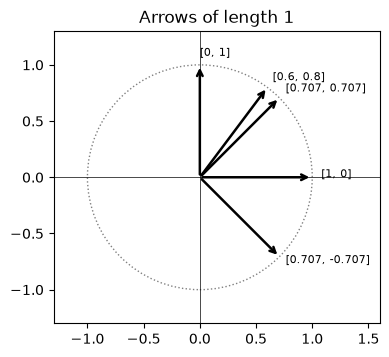

In [5]:
# Draw a few arrows of length 1. They all end on a circle of radius 1.
arrows = {"[1, 0]": [1, 0], "[0, 1]": [0, 1], "[0.6, 0.8]": [0.6, 0.8],
          "[0.707, 0.707]": [0.707, 0.707], "[0.707, -0.707]": [0.707, -0.707]}
fig, ax = plt.subplots(figsize=(4, 4))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, ls=":", color="gray"))
for name, (x, y) in arrows.items():
    ax.annotate("", xy=(x, y), xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=1.8))
    ax.text(x * 1.08, y * 1.08, name, fontsize=8)
ax.set_xlim(-1.3, 1.6); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal")
ax.axhline(0, c="k", lw=0.5); ax.axvline(0, c="k", lw=0.5)
ax.set_title("Arrows of length 1"); plt.tight_layout(); plt.show()

**What just happened?** `[3, 4]` has length 5; dividing by 5 gives `[0.6, 0.8]`, which has length 1. Every arrow of length 1 ends on the dotted circle. Soon you will see that a (simple) qubit is exactly such an arrow.

### 3.2 Matrices: machines that transform vectors

**What it is.** A **matrix** is a grid of numbers. A 2x2 matrix is a little machine: you put a 2-number vector in, and a new 2-number vector comes out.

**Simple analogy.** A photocopier with settings: it can flip, rotate or stretch the picture you feed it.

**How it works.** Each output number is "a row of the matrix times the input, added up":

$$\begin{pmatrix} a & b \\ c & d \end{pmatrix}\begin{pmatrix} x \\ y \end{pmatrix} = \begin{pmatrix} a x + b y \\ c x + d y \end{pmatrix}$$

Example by hand: $\begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}\begin{pmatrix} 3 \\ 4 \end{pmatrix} = \begin{pmatrix} 0\cdot3 + 1\cdot4 \\ 1\cdot3 + 0\cdot4 \end{pmatrix} = \begin{pmatrix} 4 \\ 3 \end{pmatrix}$. This machine **swaps** the two numbers. In Python, `@` means "feed the vector into the matrix".

In [6]:
def machine_by_hand(M, v):
    """Matrix times vector, written out step by step like on paper."""
    return [int(M[0][0] * v[0] + M[0][1] * v[1]),
            int(M[1][0] * v[0] + M[1][1] * v[1])]

swap    = np.array([[0, 1], [1, 0]])        # swaps the two numbers
stretch = np.array([[2, 0], [0, 1]])        # doubles the first number
rotate  = np.array([[0, -1], [1, 0]])       # turns the arrow a quarter turn (90 degrees) anticlockwise

v = np.array([3, 4])
for name, M in [("swap", swap), ("stretch", stretch), ("rotate", rotate)]:
    out = M @ v
    print(f"{name:8} by hand {machine_by_hand(M, v)}   numpy {out}   length before {np.linalg.norm(v):.1f}, after {np.linalg.norm(out):.2f}")

swap     by hand [4, 3]   numpy [4 3]   length before 5.0, after 5.00
stretch  by hand [6, 4]   numpy [6 4]   length before 5.0, after 7.21
rotate   by hand [-4, 3]   numpy [-4  3]   length before 5.0, after 5.00


**What just happened?** Swap and rotate keep the arrow's length at 5. Stretch makes it longer (about 7.2). In quantum computing only the **length-keeping** machines are allowed, because, as you will see next, the length is tied to "the probabilities add up to 100%". A length-keeping matrix is called **unitary**.

### 3.3 Probabilities as squared lengths

**What it is.** A **probability** is a number between 0 and 1 that says how likely something is (0.25 means 25%, "one time in four"). For a qubit, the probability of each result is the **square** of the matching number in its list.

**Why squares?** Take the arrow `[0.6, 0.8]`. By Pythagoras its squared length is $0.6^2 + 0.8^2 = 0.36 + 0.64 = 1$. So the squares are two numbers that always add up to exactly 1, just like probabilities must. Any arrow of length 1 gives valid probabilities this way, and a length-keeping machine (a unitary) keeps them valid.

**A second reason it matters.** Squares are never negative. So the numbers in the list may be negative (which is what allows cancelling), while the probabilities stay positive.

In [7]:
state = np.array([0.6, 0.8])
probs = state ** 2
print("numbers:", state, " squared:", probs, " sum of squares:", probs.sum())

state_neg = np.array([0.6, -0.8])           # a minus sign...
print("numbers:", state_neg, " squared:", state_neg ** 2, " (same probabilities!)")

numbers: [0.6 0.8]  squared: [0.36 0.64]  sum of squares: 1.0
numbers: [ 0.6 -0.8]  squared: [0.36 0.64]  (same probabilities!)


**What just happened?** `[0.6, 0.8]` means "36% chance of 0, 64% chance of 1". `[0.6, -0.8]` gives the **same** probabilities. The minus sign is invisible if you only measure once, but it changes what happens when the qubit goes through more gates. That hidden sign is the ingredient that coins do not have.

### 3.4 Complex numbers, just enough

**What it is.** A **complex number** is a number with two parts, written $a + b\,i$, where $i$ is a special number with $i \times i = -1$. Python writes $i$ as `1j`.

**Simple analogy.** A normal number is a position on a line. A complex number is a position on a flat map: $a$ steps east and $b$ steps north. Its **size** is the distance from the centre: $\sqrt{a^2 + b^2}$ (Pythagoras again).

**How it works (check by hand).**
- $i \times i = -1$.
- The size of $0.6 + 0.8i$ is $\sqrt{0.36 + 0.64} = 1$.
- Multiplying by $i$ turns a number a quarter turn on the map: $i \times (1 + 0i) = 0 + 1i$.

**Why quantum needs them.** The numbers in a qubit's list are in general complex. Their **direction** on the map is called the **phase**. "Negative" is just one special direction (pointing west). For a first understanding, positive and negative real numbers are enough, and that is what most of this notebook uses. The probability rule becomes "**size squared**", written $|a + bi|^2 = a^2 + b^2$.

In [8]:
i = 1j
print("i * i =", i * i)                       # -1
z = 0.6 + 0.8j
print("size of 0.6+0.8i by hand:", (0.6**2 + 0.8**2) ** 0.5, "  numpy abs:", abs(z))
print("i * 1 =", i * 1, "  (a quarter turn on the map)")
print("size squared of 0.6+0.8i =", abs(z) ** 2, " -> this is how a complex amplitude becomes a probability")

i * i = (-1+0j)
size of 0.6+0.8i by hand: 1.0   numpy abs: 1.0
i * 1 = 1j   (a quarter turn on the map)
size squared of 0.6+0.8i = 1.0  -> this is how a complex amplitude becomes a probability


## 4. A qubit is a list of 2 numbers

**What it is.** A **qubit** is described by a list of 2 numbers called **amplitudes**: the first belongs to the result 0, the second to the result 1. The squares of their sizes are the probabilities of reading 0 or 1, so they must add up to 1.

**Simple analogy.** An arrow of length 1 on the circle you drew in section 3.1. Pointing right means "surely 0", pointing up means "surely 1", pointing in between means "a mix".

**How it works.** Physicists write the two basic states with a funny bracket called a **ket**: $|0\rangle$ is the list `[1, 0]` and $|1\rangle$ is the list `[0, 1]`. A general qubit is $\alpha|0\rangle + \beta|1\rangle$ = `[alpha, beta]`. Some famous ones:

| Name | List | Probability of 0 | Probability of 1 |
|---|---|---|---|
| $\lvert0\rangle$ | `[1, 0]` | 1 | 0 |
| $\lvert1\rangle$ | `[0, 1]` | 0 | 1 |
| $\lvert+\rangle$ ("plus") | `[0.707, 0.707]` | 0.5 | 0.5 |
| $\lvert-\rangle$ ("minus") | `[0.707, -0.707]` | 0.5 | 0.5 |

(0.707 is $1/\sqrt2$, because $0.707^2 = 0.5$.)

In [9]:
ket0  = np.array([1, 0])
ket1  = np.array([0, 1])
plus  = np.array([1, 1]) / np.sqrt(2)
minus = np.array([1, -1]) / np.sqrt(2)

def describe(name, q):
    p = np.abs(q) ** 2                         # probability = size squared
    ok = np.isclose(p.sum(), 1)
    print(f"{name:6} list {np.round(q, 3)}  P(0)={p[0]:.2f}  P(1)={p[1]:.2f}  valid qubit: {ok}")

for name, q in [("|0>", ket0), ("|1>", ket1), ("|+>", plus), ("|->", minus), ("[.6,.8]", np.array([0.6, 0.8]))]:
    describe(name, q)
describe("[1,1]", np.array([1, 1]))            # not a valid qubit: squares add up to 2, not 1

|0>    list [1 0]  P(0)=1.00  P(1)=0.00  valid qubit: True
|1>    list [0 1]  P(0)=0.00  P(1)=1.00  valid qubit: True
|+>    list [0.707 0.707]  P(0)=0.50  P(1)=0.50  valid qubit: True
|->    list [ 0.707 -0.707]  P(0)=0.50  P(1)=0.50  valid qubit: True
[.6,.8] list [0.6 0.8]  P(0)=0.36  P(1)=0.64  valid qubit: True
[1,1]  list [1 1]  P(0)=1.00  P(1)=1.00  valid qubit: False


**What just happened?** Valid qubits are lists whose squared sizes add up to 1. `[1, 1]` is not a valid qubit (it would mean 200% probability). $|+\rangle$ and $|-\rangle$ have the same 50/50 odds but are different states, because of the minus sign.

**When the "list of 2 numbers" picture is enough, and when not.** It is exactly right for one qubit. For several qubits the list grows (section 7), and a qubit inside an entangled group no longer has its own list (section 8).

## 5. A gate is a 2x2 matrix

**What it is.** A **quantum gate** is an operation on qubits. For one qubit it is a 2x2 **unitary** matrix (a length-keeping machine from section 3.2). Applying a gate = matrix times the qubit's list.

**Simple analogy.** Turning the arrow on the circle. Gates rotate or reflect the arrow but never stretch it.

**How it works.** Three gates you will meet everywhere:

| Gate | Matrix | What it does |
|---|---|---|
| **X** (quantum NOT) | $\begin{pmatrix}0&1\\1&0\end{pmatrix}$ | swaps the two numbers: $\lvert0\rangle \leftrightarrow \lvert1\rangle$ |
| **Z** (phase flip) | $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$ | puts a minus sign on the second number |
| **H** (Hadamard) | $\frac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ | turns $\lvert0\rangle$ into $\lvert+\rangle$ and $\lvert1\rangle$ into $\lvert-\rangle$ ("start spinning the coin") |

**By hand:** $H|0\rangle = \frac{1}{\sqrt2}\begin{pmatrix}1\cdot1 + 1\cdot0\\ 1\cdot1 + (-1)\cdot0\end{pmatrix} = \begin{pmatrix}0.707\\0.707\end{pmatrix} = |+\rangle$.

In [10]:
X = np.array([[0, 1], [1, 0]])
Z = np.array([[1, 0], [0, -1]])
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)

print("X|0> =", X @ ket0, "   (now it is |1>)")
print("Z|+> =", np.round(Z @ plus, 3), "   (now it is |->)")
print("H|0> =", np.round(H @ ket0, 3), "   (now it is |+>)")
print("H|1> =", np.round(H @ ket1, 3), "  (now it is |->)")

# Check: gates keep the length at 1 (they are unitary)
for name, G in [("X", X), ("Z", Z), ("H", H)]:
    q = np.array([0.6, 0.8])
    print(f"length of {name} applied to [0.6, 0.8]: {np.linalg.norm(G @ q):.3f}")

X|0> = [0 1]    (now it is |1>)
Z|+> = [ 0.707 -0.707]    (now it is |->)
H|0> = [0.707 0.707]    (now it is |+>)
H|1> = [ 0.707 -0.707]   (now it is |->)
length of X applied to [0.6, 0.8]: 1.000
length of Z applied to [0.6, 0.8]: 1.000
length of H applied to [0.6, 0.8]: 1.000


**What just happened?** Each gate is a small matrix, and applying it is one matrix-times-vector step. None of them changes the length, so probabilities always stay valid. Notebook [01](01_quantum_computing_basics.ipynb) adds more gates (Y, S, T and rotations by any angle) and builds them into a full simulator.

**When to use which.** X when you want to flip a bit; H to create (or undo) a 50/50 superposition; Z to hide information in a sign that later gates can turn into a visible difference.

## 6. Measurement is random sampling

**What it is.** **Measuring** a qubit gives 0 or 1 at random, with the probabilities from section 3.3. After the measurement the qubit *is* the result you saw (it **collapses**): measuring again gives the same answer. One run of a quantum program ending in a measurement is called a **shot**. Because each shot is random, programs are run hundreds or thousands of times and the results are counted.

**Simple analogy.** Rolling a loaded die. One roll tells you little; a thousand rolls tell you the odds.

**How it works.** In code, "measure" is just "draw a random result with these probabilities". Let us put a fair coin and a $|+\rangle$ qubit side by side.

In [11]:
def flip_coin(shots, rng):
    """A fair coin: 0 (heads) or 1 (tails), 50/50."""
    return rng.choice([0, 1], size=shots)

def measure(qubit, shots, rng):
    """Measure a qubit many times: draw 0 or 1 with probability = size squared."""
    p = np.abs(qubit) ** 2
    return rng.choice([0, 1], size=shots, p=p)

shots = 1000
coin_results  = flip_coin(shots, rng)
qubit_results = measure(plus, shots, rng)
print("first 20 coin flips:      ", coin_results[:20])
print("first 20 qubit shots |+>: ", qubit_results[:20])
print("coin  counts:", Counter(coin_results.tolist()))
print("qubit counts:", Counter(qubit_results.tolist()))
print("qubit [0.6, 0.8] counts:", Counter(measure(np.array([0.6, 0.8]), shots, rng).tolist()), "(expect about 360 / 640)")

first 20 coin flips:       [0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0]
first 20 qubit shots |+>:  [1 1 1 1 1 1 0 1 0 0 0 1 0 0 0 0 0 1 0 1]
coin  counts: Counter({1: 509, 0: 491})
qubit counts: Counter({0: 509, 1: 491})
qubit [0.6, 0.8] counts: Counter({1: 633, 0: 367}) (expect about 360 / 640)


    10 shots -> estimated P(1) = 0.700   (error 0.060)
    30 shots -> estimated P(1) = 0.667   (error 0.027)
   100 shots -> estimated P(1) = 0.650   (error 0.010)
   300 shots -> estimated P(1) = 0.657   (error 0.017)
  1000 shots -> estimated P(1) = 0.625   (error 0.015)
  3000 shots -> estimated P(1) = 0.623   (error 0.017)
 10000 shots -> estimated P(1) = 0.643   (error 0.003)


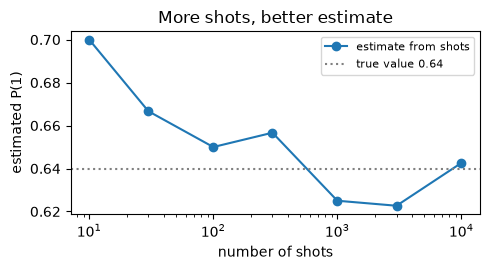

In [12]:
# How many shots do you need? Estimate P(1) of the [0.6, 0.8] qubit (true value 0.64)
shot_list = [10, 30, 100, 300, 1000, 3000, 10000]
estimates = [measure(np.array([0.6, 0.8]), s, rng).mean() for s in shot_list]
for s, e in zip(shot_list, estimates):
    print(f"{s:6} shots -> estimated P(1) = {e:.3f}   (error {abs(e - 0.64):.3f})")

plt.figure(figsize=(5, 2.8))
plt.semilogx(shot_list, estimates, "o-", label="estimate from shots")
plt.axhline(0.64, color="gray", ls=":", label="true value 0.64")
plt.xlabel("number of shots"); plt.ylabel("estimated P(1)"); plt.legend(fontsize=8)
plt.title("More shots, better estimate"); plt.tight_layout(); plt.show()

**What just happened?**
- The coin and the $|+\rangle$ qubit produce results that look **exactly the same**: about 500 zeros and 500 ones. Measuring once cannot tell them apart. The difference appears only when we apply more gates before measuring (section 9).
- The estimate wanders less and less around the true value as shots grow (any single run can still be a little lucky or unlucky). The typical error shrinks like $1/\sqrt{\text{shots}}$: 100 shots give about ±5%, 10,000 shots about ±0.5%. Every number you read from real quantum hardware is such an estimate.

**Where the coin picture breaks again.** You can look at a coin while it lands and not disturb it. You cannot peek at a qubit's amplitudes: measuring destroys the superposition and gives only one bit.

## 7. Two qubits, and why the list doubles each time

**What it is.** Two qubits together have four possible results: 00, 01, 10, 11. So their state is a list of **4** amplitudes, one per result. Three qubits need 8, and n qubits need $2^n$.

**Simple analogy.** A row of light switches. With n switches there are $2^n$ on/off patterns. An ordinary computer stores one pattern; a quantum state has one amplitude for **every** pattern.

**How it works.** If the two qubits are independent, the 4-number list is made by multiplying every number of the first list with every number of the second. This is called the **tensor product** (numpy: `np.kron`). By hand, for $|0\rangle$ = `[1, 0]` and `[0.6, 0.8]`:

`[1*0.6, 1*0.8, 0*0.6, 0*0.8] = [0.6, 0.8, 0, 0]`, in the order 00, 01, 10, 11.

In [13]:
two = np.kron(ket0, np.array([0.6, 0.8]))
labels = ["00", "01", "10", "11"]
print("two-qubit list:", two)
for lab, a in zip(labels, two):
    print(f"  result {lab}: amplitude {a:+.2f}, probability {a**2:.2f}")

three = np.kron(np.kron(plus, plus), plus)     # three qubits, each 50/50
print("\nthree |+> qubits ->", len(three), "amplitudes, each", round(three[0], 3), "(probability 1/8 each)")

two-qubit list: [0.6 0.8 0.  0. ]
  result 00: amplitude +0.60, probability 0.36
  result 01: amplitude +0.80, probability 0.64
  result 10: amplitude +0.00, probability 0.00
  result 11: amplitude +0.00, probability 0.00

three |+> qubits -> 8 amplitudes, each 0.354 (probability 1/8 each)


 1 qubits ->                    2 amplitudes  ->         0.000000 GB
 2 qubits ->                    4 amplitudes  ->         0.000000 GB
 3 qubits ->                    8 amplitudes  ->         0.000000 GB
10 qubits ->                1,024 amplitudes  ->         0.000016 GB
20 qubits ->            1,048,576 amplitudes  ->         0.016777 GB
30 qubits ->        1,073,741,824 amplitudes  ->        17.179869 GB
40 qubits ->    1,099,511,627,776 amplitudes  ->    17,592.186044 GB
50 qubits -> 1,125,899,906,842,624 amplitudes  -> 18,014,398.509482 GB


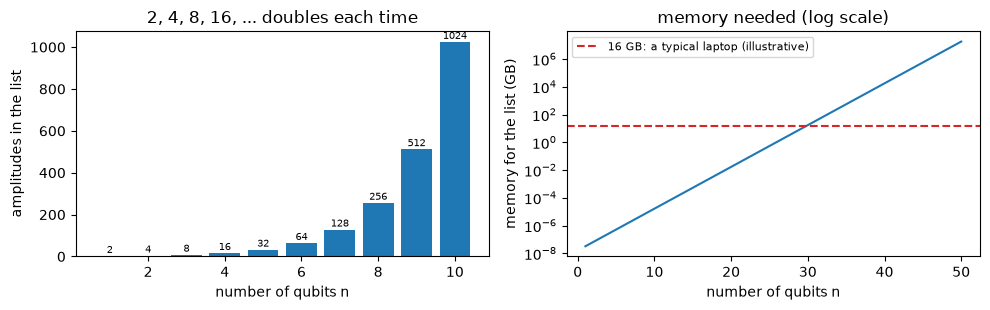

In [14]:
# The list doubles with every qubit. Each amplitude is a complex number: 16 bytes in numpy.
ns = np.arange(1, 51)
amps = 2.0 ** ns
memory_gb = amps * 16 / 1e9
for n in [1, 2, 3, 10, 20, 30, 40, 50]:
    print(f"{n:2} qubits -> {int(2**n):>20,} amplitudes  -> {2**n * 16 / 1e9:>16,.6f} GB")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
small = np.arange(1, 11)
axes[0].bar(small, 2 ** small)
for n_, v_ in zip(small, 2 ** small):
    axes[0].text(n_, v_ + 15, str(v_), ha="center", fontsize=7)
axes[0].set_xlabel("number of qubits n"); axes[0].set_ylabel("amplitudes in the list")
axes[0].set_title("2, 4, 8, 16, ... doubles each time")
axes[1].semilogy(ns, memory_gb)
axes[1].axhline(16, color="tab:red", ls="--", label="16 GB: a typical laptop (illustrative)")
axes[1].set_xlabel("number of qubits n"); axes[1].set_ylabel("memory for the list (GB)")
axes[1].set_title("memory needed (log scale)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What just happened?** 10 qubits need about 1,000 numbers; 30 qubits about a billion (17 GB); 50 qubits about $10^{15}$ (18 petabytes). This is why large quantum systems are so hard to simulate on ordinary computers, and why the physicist Richard Feynman suggested in 1982 building computers out of quantum parts.

**Careful: this does not mean a quantum computer "stores" $2^n$ answers you can read.** Measuring n qubits still gives only n bits per shot. The big list is the hidden bookkeeping; what you can get out is much smaller. Algorithms must use interference to make the useful answer likely.

## 8. Entanglement in plain words

**What it is.** Two qubits are **entangled** when their joint list cannot be split into "a list for qubit A" times "a list for qubit B". Measured one at a time each looks random, but their results are linked.

**Simple analogy (with a warning).** A pair of gloves in two closed boxes: open one box, see a left glove, and you instantly know the other box holds the right one. This captures the **linked results**. It breaks because the gloves were decided from the start. For entangled qubits, experiments in other measurement directions show correlations stronger than any "decided from the start" plan can produce (this is **Bell's theorem**, tested in experiments that won the 2022 Nobel Prize in Physics). Also, entanglement cannot send messages: each side alone just sees random 0s and 1s.

**How it works.** The classic recipe makes a **Bell pair**:
1. Start with two qubits at 00: the list `[1, 0, 0, 0]`.
2. Apply H to the first qubit: `[0.707, 0, 0.707, 0]` (first qubit 50/50, second still 0).
3. Apply **CNOT**, a two-qubit gate: "if the first qubit is 1, flip the second". It swaps the amplitudes of 10 and 11.
4. Result: `[0.707, 0, 0, 0.707]`, that is $(|00\rangle + |11\rangle)/\sqrt2$. Only 00 and 11 are possible.

In [15]:
# CNOT as a 4x4 matrix (order 00, 01, 10, 11): it swaps the last two entries
CNOT = np.array([[1, 0, 0, 0],
                 [0, 1, 0, 0],
                 [0, 0, 0, 1],
                 [0, 0, 1, 0]])
I = np.eye(2)                                   # "do nothing" to a qubit

state = np.array([1, 0, 0, 0])                  # step 1: |00>
state = np.kron(H, I) @ state                   # step 2: H on the first qubit, nothing on the second
print("after H on qubit A:", np.round(state, 3))
state = CNOT @ state                            # step 3: CNOT
print("after CNOT (Bell pair):", np.round(state, 3))

def measure_pair(state, shots, rng):
    p = np.abs(state) ** 2
    return rng.choice(["00", "01", "10", "11"], size=shots, p=p)

results = measure_pair(state, 1000, rng)
print("\n1000 shots:", dict(sorted(Counter(results.tolist()).items())))
print("qubit A alone: P(1) =", np.mean([r[0] == "1" for r in results]))
print("qubit B alone: P(1) =", np.mean([r[1] == "1" for r in results]))
print("A and B agree in", np.mean([r[0] == r[1] for r in results]) * 100, "% of shots")

after H on qubit A: [0.707 0.    0.707 0.   ]
after CNOT (Bell pair): [0.707 0.    0.    0.707]

1000 shots: {'00': 493, '11': 507}
qubit A alone: P(1) = 0.507
qubit B alone: P(1) = 0.507
A and B agree in 100.0 % of shots


In [16]:
# Why can't we split it into two separate lists?
# Independent qubits [a, b] and [c, d] give [a*c, a*d, b*c, b*d].
# For the Bell pair we would need a*d = 0 and b*c = 0 but a*c = 0.707 and b*d = 0.707.
# a*d = 0 means a = 0 or d = 0. But a = 0 makes a*c = 0, and d = 0 makes b*d = 0. Contradiction.
# A quick numeric check: try many random independent pairs and see how close they get.
best = 0
for _ in range(20000):
    qa = rng.normal(size=2); qa /= np.linalg.norm(qa)
    qb = rng.normal(size=2); qb /= np.linalg.norm(qb)
    overlap = abs(np.kron(qa, qb) @ state) ** 2      # 1.0 would mean "identical to the Bell pair"
    best = max(best, overlap)
print(f"best match of any independent pair to the Bell pair: {best:.3f}  (never reaches 1.0; the maximum is 0.5)")

best match of any independent pair to the Bell pair: 0.500  (never reaches 1.0; the maximum is 0.5)


**What just happened?** The Bell pair only ever gives 00 or 11. Each qubit on its own is a fair 50/50, yet the two always agree. No pair of separate one-qubit lists reproduces it (the best possible match is 50%). That is entanglement.

**When it matters.** Entanglement is a necessary ingredient of quantum speed-ups (circuits with very little entanglement can usually be simulated cheaply on ordinary computers), but it is not enough on its own. It is also what makes qubits fragile: any accidental entanglement with the environment scrambles the computation (**decoherence**).

## 9. Interference: H then H returns to 0

**What it is.** **Interference** is amplitudes adding up or cancelling when several "paths" lead to the same result. It is the real engine of quantum computing.

**Simple analogy.** The maze from section 2: arrows on routes to the same exit are added; opposite arrows cancel.

**How it works.** Compare a coin with a qubit, each "randomised twice":
- **Coin:** a random flip is the probability machine $\begin{pmatrix}0.5&0.5\\0.5&0.5\end{pmatrix}$ (only positive numbers). Two random flips are still 50/50. Randomness never undoes itself.
- **Qubit:** H applied once gives 50/50. H applied **twice** gives back $|0\rangle$ with certainty.

In [17]:
coin_flip = np.array([[0.5, 0.5], [0.5, 0.5]])     # probabilities, all positive
start = np.array([1.0, 0.0])                       # coin surely heads (0)
print("coin, flipped once :", coin_flip @ start)
print("coin, flipped twice:", coin_flip @ coin_flip @ start, "  <- still 50/50")

q_once = H @ ket0
q_twice = H @ H @ ket0
print("\nqubit after H   :", r3(q_once), " probabilities", r3(q_once ** 2))
print("qubit after H, H:", r3(q_twice), " probabilities", r3(q_twice ** 2), "  <- back to 0!")
print("\nmeasured 1000 times after H, H:", Counter(measure(q_twice, 1000, rng).tolist()))

coin, flipped once : [0.5 0.5]
coin, flipped twice: [0.5 0.5]   <- still 50/50

qubit after H   : [0.707 0.707]  probabilities [0.5 0.5]
qubit after H, H: [1. 0.]  probabilities [1. 0.]   <- back to 0!

measured 1000 times after H, H: Counter({0: 1000})


In [18]:
# Follow the paths by hand. Start at 0, apply H (step 1), then H (step 2).
# H's entries: H[out, in]. Going 0->0, 0->1, 1->0 gives +0.707; going 1->1 gives -0.707.
print("paths that end at 0:")
total0 = 0
for middle in [0, 1]:
    a = H[middle, 0] * H[0, middle]
    total0 += a
    print(f"   0 -> {middle} -> 0 : {H[middle, 0]:+.3f} * {H[0, middle]:+.3f} = {a:+.3f}")
print(f"   total amplitude for 0: {total0:+.3f}  (the two paths ADD up)")

print("paths that end at 1:")
total1 = 0
for middle in [0, 1]:
    a = H[middle, 0] * H[1, middle]
    total1 += a
    print(f"   0 -> {middle} -> 1 : {H[middle, 0]:+.3f} * {H[1, middle]:+.3f} = {a:+.3f}")
print(f"   total amplitude for 1: {total1:+.3f}  (the two paths CANCEL)")

paths that end at 0:
   0 -> 0 -> 0 : +0.707 * +0.707 = +0.500
   0 -> 1 -> 0 : +0.707 * +0.707 = +0.500
   total amplitude for 0: +1.000  (the two paths ADD up)
paths that end at 1:
   0 -> 0 -> 1 : +0.707 * +0.707 = +0.500
   0 -> 1 -> 1 : +0.707 * -0.707 = -0.500
   total amplitude for 1: +0.000  (the two paths CANCEL)


In [19]:
# Hide a minus sign in the middle (a Z gate): now the paths to 0 cancel and we surely get 1.
q = H @ Z @ H @ ket0
print("H, Z, H on |0> ->", r3(q), "  probabilities", r3(q ** 2))
print("Measured once, |+> and |-> looked identical (50/50). After a final H they give 0 and 1 for sure:")
print("   H|+> =", r3(H @ plus), "   H|-> =", r3(H @ minus))

H, Z, H on |0> -> [0. 1.]   probabilities [0. 1.]
Measured once, |+> and |-> looked identical (50/50). After a final H they give 0 and 1 for sure:
   H|+> = [1. 0.]    H|-> = [0. 1.]


**What just happened?**
- For the coin, probabilities only add, so randomness piles up. For the qubit, amplitudes can be negative, so the two paths to 1 (+0.5 and −0.5) cancel and the two paths to 0 (+0.5 and +0.5) add up to 1.
- A hidden minus sign (from Z) is invisible to a single measurement, but a final H turns it into a definite, visible answer. "Hide information in a sign (a **phase**), then interfere" is the core trick of every quantum algorithm, including Grover search in notebook [02](02_quantum_algorithms.ipynb).
- This is why section 6's coin and qubit looked the same but are not the same.

**When interference helps and when not.** It helps when a problem has structure that lets an algorithm arrange the cancellations (factoring, simulating molecules, some search problems). For an unstructured problem with no such structure, there is nothing to arrange, and the quantum computer has no special advantage.

## 10. Myths vs facts

| Myth | Fact |
|---|---|
| "A quantum computer tries all answers at once and picks the best." | It holds amplitudes for many patterns, but one measurement gives one answer of n bits. Speed-ups come from **interference** arranged by a clever algorithm, and only for problems with special structure. |
| "Quantum computers are faster at everything." | For most tasks (spreadsheets, web pages, video, most AI training) there is no known speed-up, and quantum hardware is much slower per operation. |
| "Quantum computers will replace your laptop (or GPUs)." | They are special-purpose machines, used through the cloud next to ordinary computers, a bit like a lab instrument. Your laptop is still needed to control them and to process their results. |
| "A qubit is just 0 and 1 at the same time." | A qubit has two amplitudes that can be negative or complex. "Both at once" hides the part that matters: the signs that let paths cancel. |
| "n qubits store $2^n$ answers you can read." | You can read only n bits per shot. Reading out the full list would need an enormous number of runs. |
| "Entanglement lets you send messages faster than light." | Each side alone sees random results; no message can be sent this way. |
| "More qubits always means a better computer." | Error rates matter as much. A machine with fewer, cleaner qubits can be more useful. |
| "Quantum AI will make chatbots and neural networks super fast." | There is no evidence of that today. Loading data in and reading results out are major bottlenecks. Notebooks 03 and 05 test this honestly. |
| "Quantum computers have already broken internet encryption." | Not yet. It would need far larger, error-corrected machines. But the move to new "post-quantum" encryption has already started (notebook 04). |

## 11. Quantum Computing vs Quantum AI vs Quantum ML

These three words are often mixed up. Here is the map.

- **Quantum Computing** is the foundation: qubits, gates, measurement and quantum algorithms. This is **Part 1** of the track (notebooks 00, 01, 02).
- **Quantum AI** is the broad meeting point of quantum computing and AI. It has two directions:
  - **Quantum for AI**: use quantum computers to do machine learning. This is **Quantum ML (QML)**. Mostly research today.
  - **AI for quantum**: use ordinary machine learning to build, calibrate and error-correct quantum computers. Already useful today.
- **Quantum ML** is therefore one part of Quantum AI. It uses the gates and measurements of quantum computing as a new kind of trainable model.

Diagram: how the three ideas relate, and which notebook covers what.

```mermaid
flowchart TD
    QC[Quantum Computing<br/>qubits, gates, measurement,<br/>algorithms<br/>Part 1: notebooks 00, 01, 02] --> QAI[Quantum AI<br/>where quantum computing meets AI<br/>Part 2: notebooks 03, 04, 05]
    ML[Classical AI and ML<br/>models, training, evaluation] --> QAI
    QAI --> Q4AI[Quantum for AI<br/>= Quantum ML QML<br/>variational circuits, quantum kernels<br/>notebooks 03 and 05]
    QAI --> AI4Q[AI for quantum<br/>ML for decoders, calibration, control<br/>notebook 04]
    QC --> ALG[Quantum algorithms<br/>Grover, Shor, VQE, QAOA<br/>notebook 02]
```

| | Quantum Computing | Quantum AI | Quantum ML |
|---|---|---|---|
| **Main question** | How do qubits and quantum algorithms work? | How do quantum computing and AI help each other? | Can a quantum circuit be a useful machine-learning model? |
| **Typical example** | Grover search, Shor factoring | a neural network that corrects qubit errors; a quantum classifier | a variational quantum classifier; a quantum-kernel SVM |
| **Status (as of late 2026)** | small, noisy machines; error correction is improving | AI for quantum is used in practice; quantum for AI is research | research; classical models usually win on classical data |
| **Where in this track** | 00, 01, 02 | 03, 04, 05 | 03, 05 |

## 12. Glossary: 20 terms in plain words

| # | Term | Plain meaning |
|---|---|---|
| 1 | **Bit** | the smallest unit of information: 0 or 1 |
| 2 | **Qubit** | a quantum bit: described by two amplitudes; gives 0 or 1 when measured |
| 3 | **Amplitude** | one number in a qubit's list; its size squared is a probability; it can be negative or complex |
| 4 | **Superposition** | a state with non-zero amplitude on more than one result |
| 5 | **Measurement** | reading a qubit; gives a random 0 or 1 and ends the superposition (collapse) |
| 6 | **Shot** | one run of a quantum program, ending in one measurement result |
| 7 | **Born rule** | probability of a result = size of its amplitude, squared |
| 8 | **Ket** | the bracket notation $\lvert0\rangle$, $\lvert1\rangle$, $\lvert\psi\rangle$ for quantum states |
| 9 | **Vector** | a list of numbers, drawn as an arrow |
| 10 | **Matrix** | a grid of numbers that transforms vectors (a "machine") |
| 11 | **Complex number** | a number $a + bi$ with $i \times i = -1$; a point on a flat map |
| 12 | **Phase** | the direction of an amplitude (for real numbers: its sign); invisible in one measurement, visible after interference |
| 13 | **Quantum gate** | an operation on qubits; a unitary matrix |
| 14 | **Unitary** | a length-keeping matrix, so probabilities stay valid and the step can be undone |
| 15 | **Hadamard (H)** | the gate that turns $\lvert0\rangle$ into the 50/50 state $\lvert+\rangle$ and back |
| 16 | **CNOT** | a two-qubit gate: flip the second qubit if the first is 1; used to create entanglement |
| 17 | **Entanglement** | a joint state of qubits that cannot be split into separate states; results are linked |
| 18 | **Interference** | amplitudes from different paths adding up or cancelling |
| 19 | **Decoherence / noise** | the environment disturbing qubits and destroying their quantum behaviour; the main engineering problem |
| 20 | **Quantum machine learning (QML)** | using quantum circuits as trainable models for data; part of Quantum AI |

## 13. Self-check quiz

Try each question first, then open the answer. Some questions have a code cell below so you can check yourself.

**Q1.** Is `[0.8, 0.6]` a valid qubit? What are its probabilities of 0 and 1?

<details><summary>Answer</summary>

Yes: $0.8^2 + 0.6^2 = 0.64 + 0.36 = 1$. P(0) = 0.64, P(1) = 0.36.
</details>

**Q2.** Is `[0.5, 0.5]` a valid qubit?

<details><summary>Answer</summary>

No: $0.25 + 0.25 = 0.5$, not 1. Divide by its length ($\sqrt{0.5} \approx 0.707$) to get `[0.707, 0.707]` = $\lvert+\rangle$.
</details>

**Q3.** What is X applied to `[0.6, 0.8]`?

<details><summary>Answer</summary>

X swaps the numbers: `[0.8, 0.6]`.
</details>

**Q4.** How many amplitudes do 5 qubits have? And 20?

<details><summary>Answer</summary>

$2^5 = 32$ and $2^{20} = 1{,}048{,}576$ (about a million).
</details>

**Q5.** You measure $\lvert+\rangle$ and $\lvert-\rangle$ 1000 times each. Can you tell them apart from the counts?

<details><summary>Answer</summary>

No. Both give about 500 zeros and 500 ones. Apply H first: then $\lvert+\rangle$ always gives 0 and $\lvert-\rangle$ always gives 1.
</details>

**Q6.** Why does H followed by H return a qubit to 0, while flipping a coin twice does not return it to heads?

<details><summary>Answer</summary>

Amplitudes can be negative. The two paths to 1 have amplitudes +0.5 and −0.5 and cancel; the two paths to 0 add up to 1. Coin probabilities are never negative, so nothing cancels.
</details>

**Q7.** In a Bell pair, qubit A is measured and gives 1. What will qubit B give?

<details><summary>Answer</summary>

1 (the Bell pair $(\lvert00\rangle + \lvert11\rangle)/\sqrt2$ only gives 00 or 11). But B alone, before anyone looks at A, is a fair 50/50, so no message is sent.
</details>

**Q8.** True or false: "A 50-qubit quantum computer checks $2^{50}$ answers at once and tells you the best one."

<details><summary>Answer</summary>

False. One measurement gives 50 bits. Useful answers come only from algorithms that use interference to make the right answer likely, and only for problems with special structure.
</details>

**Q9.** What is the difference between Quantum AI and Quantum ML?

<details><summary>Answer</summary>

Quantum ML (using quantum circuits as machine-learning models) is one part of Quantum AI. Quantum AI also includes "AI for quantum": using classical ML to build and run quantum computers.
</details>

**Q10.** With 100 shots, roughly how precise is an estimated probability? With 10,000?

<details><summary>Answer</summary>

The error shrinks like $1/\sqrt{\text{shots}}$: about ±0.05 (5%) with 100 shots and about ±0.005 (0.5%) with 10,000.
</details>

In [20]:
# Check your answers to Q1-Q5 with code
q = np.array([0.8, 0.6]);  print("Q1 probabilities:", q ** 2, " sum:", (q ** 2).sum())
q = np.array([0.5, 0.5]);  print("Q2 sum of squares:", (q ** 2).sum(), "-> not valid")
print("Q3 X @ [0.6, 0.8] =", X @ np.array([0.6, 0.8]))
print("Q4 amplitudes for 5 and 20 qubits:", 2 ** 5, 2 ** 20)
print("Q5 after H: H|+> =", r3(H @ plus), " H|-> =", r3(H @ minus))

Q1 probabilities: [0.64 0.36]  sum: 1.0
Q2 sum of squares: 0.5 -> not valid
Q3 X @ [0.6, 0.8] = [0.8 0.6]
Q4 amplitudes for 5 and 20 qubits: 32 1048576
Q5 after H: H|+> = [1. 0.]  H|-> = [0. 1.]


## 14. Recap (cheat sheet)

| Idea | In one line | Tiny example |
|---|---|---|
| Bit | 0 or 1, one pattern at a time | `"A"` = `01000001` |
| Vector | a list of numbers / an arrow | `[3, 4]` has length 5 |
| Matrix | a machine that transforms vectors | swap `[[0,1],[1,0]]` turns `[3,4]` into `[4,3]` |
| Probability as squared length | squares of a length-1 arrow add up to 1 | `[0.6, 0.8]` → 0.36 and 0.64 |
| Complex number | $a + bi$, $i^2 = -1$; size $\sqrt{a^2+b^2}$ | $\lvert0.6+0.8i\rvert = 1$ |
| Qubit | list of 2 amplitudes, squared sizes sum to 1 | $\lvert+\rangle$ = `[0.707, 0.707]` |
| Gate | 2x2 unitary matrix | H$\lvert0\rangle = \lvert+\rangle$ |
| Measurement | random sampling with the Born rule; repeat for many shots | 1000 shots of $\lvert+\rangle$ ≈ 500/500 |
| Many qubits | $2^n$ amplitudes; 30 qubits ≈ 17 GB | `np.kron` builds the list |
| Entanglement | linked results, joint list cannot be split | Bell pair gives only 00 or 11 |
| Interference | amplitudes add or cancel | H then H gives 0 for sure |
| The honest summary | power comes from interference on structured problems, not from "trying everything" | see the myths table |

## 15. Interview questions (short answers)

1. **What is a qubit?** A two-level quantum system described by two complex amplitudes; measuring gives 0 or 1 with probability equal to each amplitude's size squared.
2. **Why must quantum gates be unitary?** So the total probability stays 1 and every step can be undone.
3. **Why do classical computers struggle to simulate many qubits?** The state needs $2^n$ amplitudes; memory doubles with each qubit.
4. **What is the role of interference?** It lets algorithms cancel the amplitudes of wrong answers and boost right ones; without it there is no speed-up.
5. **Does entanglement allow faster-than-light communication?** No. Each side alone sees random results.
6. **Where is quantum computing expected to help first?** Simulating chemistry, materials and physics, on future error-corrected machines.

## Further reading

- M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, Cambridge University Press, 10th anniversary edition, 2010. The standard textbook (chapters 1 and 2 cover this notebook in more depth).
- C. Bernhardt, *Quantum Computing for Everyone*, MIT Press, 2019. A gentle book that uses only high-school maths.
- A. Matuschak and M. Nielsen, *Quantum Country* (quantum.country), a free online introduction with built-in review questions.
- S. Aaronson, *Quantum Computing Since Democritus*, Cambridge University Press, 2013. Clear on what quantum computers can and cannot do.
- R. P. Feynman, "Simulating Physics with Computers", *International Journal of Theoretical Physics* 21 (1982).
- IBM Quantum Learning (the successor of the free Qiskit textbook) and the PennyLane "Quantum computing" introductions.

## Where to go next

- **Part 1, continued:** [01_quantum_computing_basics.ipynb](01_quantum_computing_basics.ipynb) builds a real statevector simulator in numpy (the same ideas, with more gates, the Bloch sphere and no-cloning). Then [02_quantum_algorithms.ipynb](02_quantum_algorithms.ipynb) shows what quantum computers are for.
- **Part 2:** [03_quantum_machine_learning.ipynb](03_quantum_machine_learning.ipynb) (quantum ML), [04_quantum_ai_tools_hardware_and_industry.ipynb](04_quantum_ai_tools_hardware_and_industry.ipynb) (tools, noise, AI for quantum), and [05_quantum_ml_on_sensor_data_fall_detection.ipynb](05_quantum_ml_on_sensor_data_fall_detection.ipynb) (quantum ML tested honestly on a real-world style task).
- Maths refreshers: [linear algebra](../14_Mathematics/01_linear_algebra.ipynb) and [probability](../14_Mathematics/03_probability.ipynb).